# Лабораторная работа № 5.2
## Параметрическая идентификация

**Выполнили:**

- Левченков Артемий Викторович;
- Бикбулатова Динара Фануровна;
- Ладыгин Максим Александрович.

**Группа** БИВТ-24-АЭ-3

**Исходные данные** — дискретный ряд распределения возраста людей, совершивших преступления в Москве в 2021 году.

$x$ — возраст, $y$ — абсолютная частота. $N$ — сумма частот, $n$ — число пар «возраст — частота».

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_table("data/moscow.txt", header=None)[0]
discrete = data.value_counts().sort_index().rename_axis("x").reset_index(name="y")
x = discrete["x"]
y = discrete["y"]
N = sum(y)
n = len(x)

print("Общая сумма частот N =", N)
print("Число пар n =", n)
display(discrete.head())

Общая сумма частот N = 32423
Число пар n = 58


,x,y
0,14,49
1,15,53
2,16,236
3,17,126
4,18,806


### 1. Параметры линейной модели

Линейная модель имеет вид $\hat y=\hat a+\hat b x$. Коэффициенты находим методом наименьших квадратов.

$$F(a,b)=\sum_{i=1}^n(y_i-(a+bx_i))^2\to\min_{a,b}.$$

$$D^*(X)=\overline{x^2}-(\bar x)^2,\qquad
\hat b=\frac{\overline{xy}-\bar x\bar y}{D^*(X)},\qquad
\hat a=\bar y-\hat b\bar x.$$

Черта обозначает среднее по $n$ парам. Наклон $\hat b$ округляем до десятых перед расчётом $\hat a$.

In [2]:
mean_x = sum(x) / n
mean_y = sum(y) / n
mean_x2 = sum(x ** 2) / n
mean_xy = sum(x * y) / n

variance_x = mean_x2 - mean_x ** 2
covariance = mean_xy - mean_x * mean_y

b = round(covariance / variance_x, 1)
a = mean_y - b * mean_x
y_model = a + b * x

equation = f"ŷ = {a:.2f} {b:+.1f}x"

print(f"Средняя X = {mean_x:.4f}")
print(f"Средняя Y = {mean_y:.4f}")
print(f"Дисперсия D*(X) = {variance_x:.4f}")
print(f"Ковариация m_xy = {covariance:.4f}")
print(f"Уравнение модели — {equation}")

Средняя X = 42.5862
Средняя Y = 559.0172
Дисперсия D*(X) = 285.0702
Ковариация m_xy = -4032.3032
Уравнение модели — ŷ = 1159.48 -14.1x


### 2. Коэффициент детерминации и сравнение с ЛР 4.1

$$R^2=1-\frac{\sum_{i=1}^n(y_i-\hat y_i)^2}{\sum_{i=1}^n(y_i-\bar y)^2}.$$

В ЛР 4.1 получили $r_{xy}=-0{,}5777$. Для сравнения вычислим $r_{xy}$ на тех же данных.

$$r_{xy}=\frac{m_{xy}}{\sigma_x^*\sigma_y^*},\qquad
\sigma_x^*=\sqrt{D^*(X)},\qquad
\sigma_y^*=\sqrt{\frac{1}{n}\sum_{i=1}^n(y_i-\bar y)^2}.$$

In [3]:
sse = sum((y - y_model) ** 2)
syy = sum((y - mean_y) ** 2)

R2 = 1 - sse / syy
sqrt_R2 = R2 ** 0.5

sigma_x = variance_x ** 0.5
sigma_y = (syy / n) ** 0.5
r = covariance / (sigma_x * sigma_y)

print(f"Сумма квадратов остатков = {sse:.2f}")
print(f"Общая сумма квадратов = {syy:.2f}")
print(f"R² = {R2:.4f}")
print(f"√R² = {sqrt_R2:.4f}")
print(f"r_xy = {r:.4f}")
print(f"|r_xy| = {abs(r):.4f}")
print(f"Разность √R² и |r_xy| по модулю = {abs(sqrt_R2 - abs(r)):.2e}")

Сумма квадратов остатков = 6604676.10
Общая сумма квадратов = 9912772.98
R² = 0.3337
√R² = 0.5777
r_xy = -0.5777
|r_xy| = 0.5777
Разность √R² и |r_xy| по модулю = 2.92e-06


После округления наклона $\sqrt{R^2}$ и $|r_{xy}|$ совпадают до четырёх знаков после запятой. Отрицательные $r_{xy}$ и $\hat b$ соответствуют нисходящей прямой.

### 3. Корреляционное поле и аппроксимирующая прямая

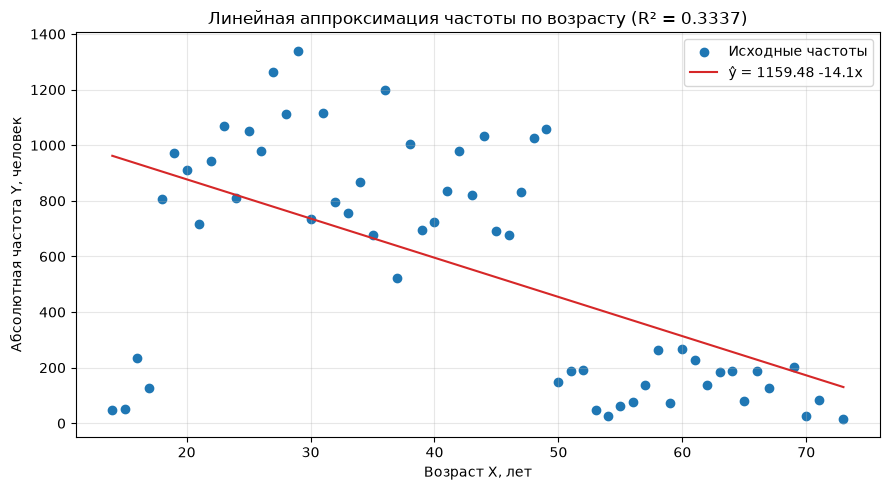

In [4]:
plt.figure(figsize=(9, 5))
plt.scatter(x, y, label="Исходные частоты")
plt.plot(x, y_model, color="tab:red", label=equation)
plt.title(f"Линейная аппроксимация частоты по возрасту (R² = {R2:.4f})")
plt.xlabel("Возраст X, лет")
plt.ylabel("Абсолютная частота Y, человек")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Вывод

Получена модель $\hat y=1159{,}48-14{,}1x$. Прямая объясняет $33{,}37\%$ разброса наблюдаемых частот относительно их среднего. Точки на графике заметно отклоняются от прямой, особенно у младших возрастов.